# Exploratory Data Analysis & Algorithm Comparison (Titanic Dataset)

This notebook demonstrates the exploratory data analysis (EDA), preprocessing, and evaluation of Machine Learning models. While the core algorithms are implemented from scratch in the `src/` directory, here we focus on visualizing the data and understanding model performance using Scikit-Learn tools like Confusion Matrices and Classification Reports.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings('ignore')

## 1. Data Loading and EDA
We use the Titanic dataset. The goal is to predict the `survived` column.

In [2]:
dataset_url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
dataset = pd.read_csv(dataset_url)

print("Dataset Shape:", dataset.shape)
print("\nMissing Values per feature:")
display(dataset.isna().sum()[dataset.isna().sum() > 0])

dataset.head()

Dataset Shape: (891, 15)

Missing Values per feature:


age            177
embarked         2
deck           688
embark_town      2
dtype: int64

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
# Select features and handle missing values
selected_features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = dataset[selected_features].copy()
y = dataset["survived"]

# Imputation
X["age"] = X["age"].fillna(X["age"].median())
X["fare"] = X["fare"].fillna(X["fare"].median())
X["embarked"] = X["embarked"].fillna(X["embarked"].mode()[0])

# Encoding categorical variables
X_encoded = pd.get_dummies(X, columns=["sex", "embarked"], drop_first=True, dtype=int)

# Train/Test Split & Scaling
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

scaler = MinMaxScaler()
X_train_normalized = scaler.fit_transform(X_train)
X_test_normalized = scaler.transform(X_test)

Accuracy: 78.21%

              precision    recall  f1-score   support

           0       0.81      0.84      0.83       110
           1       0.73      0.70      0.71        69

    accuracy                           0.78       179
   macro avg       0.77      0.77      0.77       179
weighted avg       0.78      0.78      0.78       179



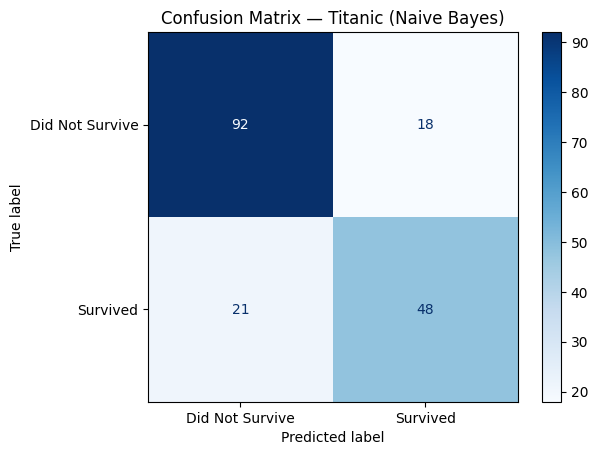

In [4]:
# Train Naive Bayes
model = GaussianNB()
model.fit(X_train_normalized, y_train)
predictions = model.predict(X_test_normalized)

print(f"Accuracy: {accuracy_score(y_test, predictions) * 100:.2f}%\n")
print(classification_report(y_test, predictions))

# Display Confusion Matrix
confusion = confusion_matrix(y_test, predictions)
display_confusion = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=["Did Not Survive", "Survived"]
)
display_confusion.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Titanic (Naive Bayes)")
plt.show()